# Heart Attack (Germany) Dataset - Exploratory Data Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.read_csv("heart_attack_germany.csv")


In [3]:
df.head()

,State,Age_Group,Heart_Attack_Incidence,Year,Gender,BMI,Smoking_Status,Alcohol_Consumption,Physical_Activity_Level,Diet_Quality,...,Cholesterol_Level,Diabetes,Urban_Rural,Socioeconomic_Status,Air_Pollution_Index,Stress_Level,Healthcare_Access,Education_Level,Employment_Status,Region_Heart_Attack_Rate
0,Lower Saxony,Youth,0,2018,Other,25.6,Former Smoker,4.2,Moderate,Average,...,154.4,0,Rural,Low,31.58,Moderate,Moderate,Primary,Retired,1.92
1,Saxony,Adult,0,2021,Female,36.7,Smoker,2.4,Low,Poor,...,75.0,1,Rural,Low,46.22,High,Easy,Primary,Unemployed,14.16
2,Hesse,Youth,1,2022,Female,28.6,Smoker,29.5,High,Poor,...,121.9,0,Urban,Middle,15.69,High,Hard,Secondary,Student,3.49
3,Lower Saxony,Adult,0,2015,Male,27.6,Non-Smoker,4.2,Moderate,Poor,...,152.3,0,Urban,Low,26.50,High,Hard,Tertiary,Student,3.24
4,Hamburg,Adult,0,2015,Female,15.2,Smoker,4.3,Moderate,Good,...,130.3,0,Urban,High,11.21,High,Moderate,Tertiary,Employed,9.98


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 275644 entries, 0 to 275643
Data columns (total 22 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   State                     275644 non-null  str    
 1   Age_Group                 275644 non-null  str    
 2   Heart_Attack_Incidence    275644 non-null  int64  
 3   Year                      275644 non-null  int64  
 4   Gender                    275644 non-null  str    
 5   BMI                       275644 non-null  float64
 6   Smoking_Status            275644 non-null  str    
 7   Alcohol_Consumption       275644 non-null  float64
 8   Physical_Activity_Level   275644 non-null  str    
 9   Diet_Quality              275644 non-null  str    
 10  Family_History            275644 non-null  int64  
 11  Hypertension              275644 non-null  int64  
 12  Cholesterol_Level         275644 non-null  float64
 13  Diabetes                  275644 non-null  int64  
 14 

In [5]:
df.tail()

,State,Age_Group,Heart_Attack_Incidence,Year,Gender,BMI,Smoking_Status,Alcohol_Consumption,Physical_Activity_Level,Diet_Quality,...,Cholesterol_Level,Diabetes,Urban_Rural,Socioeconomic_Status,Air_Pollution_Index,Stress_Level,Healthcare_Access,Education_Level,Employment_Status,Region_Heart_Attack_Rate
275639,Baden-Württemberg,Adult,0,2022,Female,27.2,Non-Smoker,2.7,High,Poor,...,114.1,0,Rural,Low,27.01,High,Easy,Primary,Unemployed,15.37
275640,Hesse,Adult,0,2021,Male,28.4,Smoker,9.5,Low,Good,...,80.8,1,Rural,Low,45.26,Moderate,Hard,Secondary,Retired,8.37
275641,North Rhine-Westphalia,Adult,0,2016,Other,33.2,Non-Smoker,7.7,Moderate,Good,...,120.7,0,Urban,Low,21.63,High,Moderate,Primary,Employed,5.11
275642,Hamburg,Youth,0,2021,Male,37.7,Former Smoker,19.3,High,Average,...,139.5,1,Urban,Low,10.29,High,Moderate,Secondary,Retired,9.13
275643,North Rhine-Westphalia,Youth,1,2019,Female,15.9,Former Smoker,16.7,High,Poor,...,142.2,0,Urban,Low,21.19,High,Easy,Tertiary,Student,4.84


In [6]:
df["Heart_Attack_Incidence"].value_counts()

Heart_Attack_Incidence
0    234278
1     41366
Name: count, dtype: int64

In [7]:
df["Gender"].value_counts()

Gender
Female    92171
Other     91872
Male      91601
Name: count, dtype: int64

In [8]:
df["State"].unique()

<StringArray>
[          'Lower Saxony',                 'Saxony',                  'Hesse',
                'Hamburg', 'North Rhine-Westphalia',                 'Berlin',
      'Baden-Württemberg',                'Bavaria']
Length: 8, dtype: str

In [9]:
df["Age_Group"].value_counts()

Age_Group
Adult    193115
Youth     82529
Name: count, dtype: int64

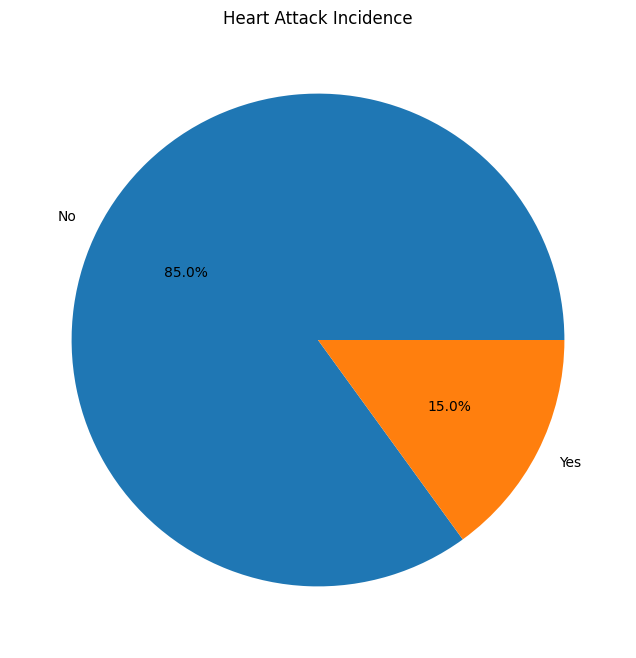

In [10]:
Incidence = df['Heart_Attack_Incidence'].map({0: "No", 1: "Yes"}).value_counts()

plt.figure(figsize=(8, 8))
plt.pie(Incidence, labels=Incidence.index, autopct='%1.1f%%')
plt.title('Heart Attack Incidence')
plt.show()


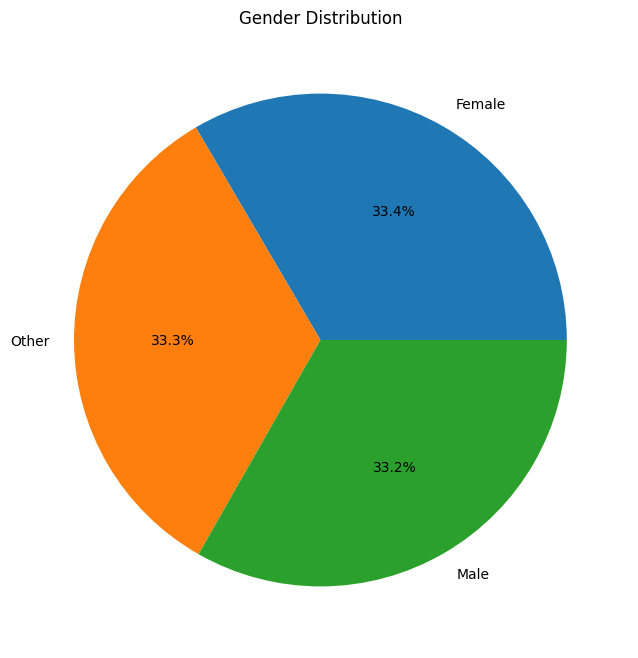

In [11]:
Gender = df['Gender'].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(Gender, labels=Gender.index, autopct='%1.1f%%')
plt.title('Gender Distribution')
plt.show()


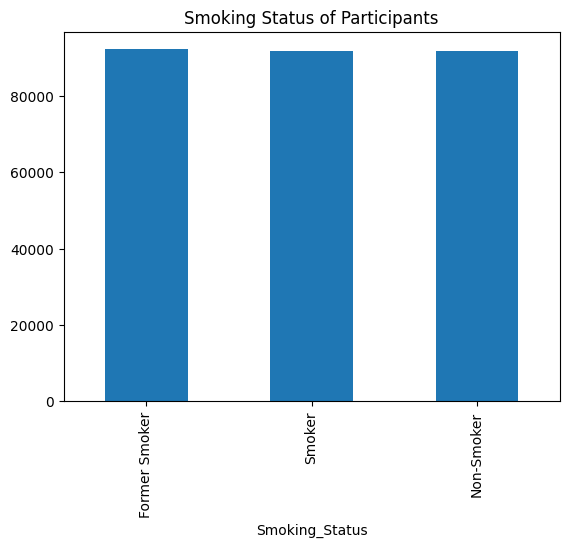

In [12]:
smoke_cnt = df['Smoking_Status'].value_counts()
smoke_cnt.plot(kind='bar')
plt.title("Smoking Status of Participants")
plt.xlabel("Smoking_Status")
plt.show()


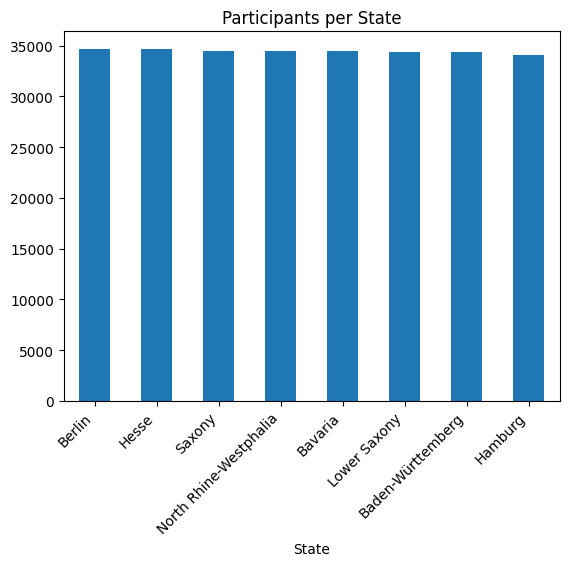

In [13]:
state_cnt = df['State'].value_counts()
state_cnt.plot(kind='bar')
plt.title("Participants per State")
plt.xlabel("State")
plt.xticks(rotation=45, ha='right')
plt.show()


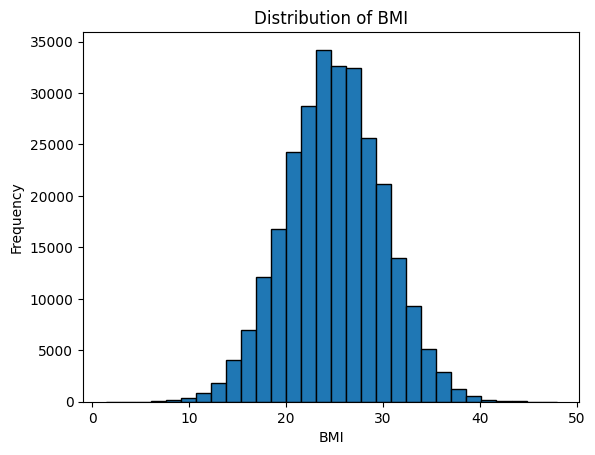

In [14]:
df["BMI"].plot(kind="hist", bins=30, edgecolor="black")
plt.title("Distribution of BMI")
plt.xlabel("BMI")
plt.show()


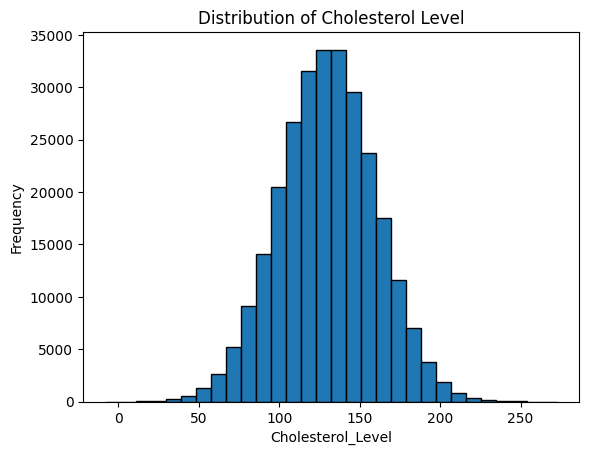

In [15]:
df["Cholesterol_Level"].plot(kind="hist", bins=30, edgecolor="black")
plt.title("Distribution of Cholesterol Level")
plt.xlabel("Cholesterol_Level")
plt.show()


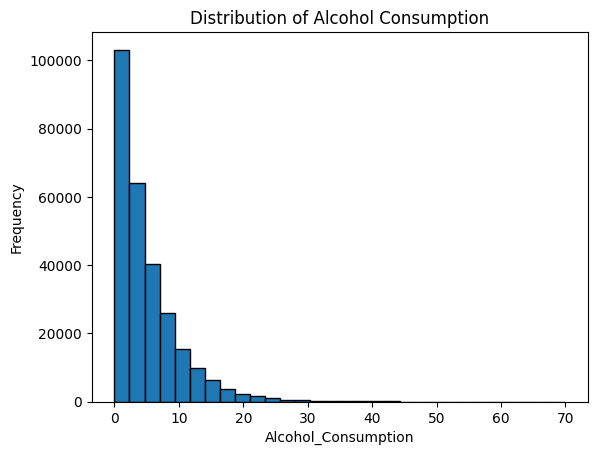

In [16]:
df["Alcohol_Consumption"].plot(kind="hist", bins=30, edgecolor="black")
plt.title("Distribution of Alcohol Consumption")
plt.xlabel("Alcohol_Consumption")
plt.show()


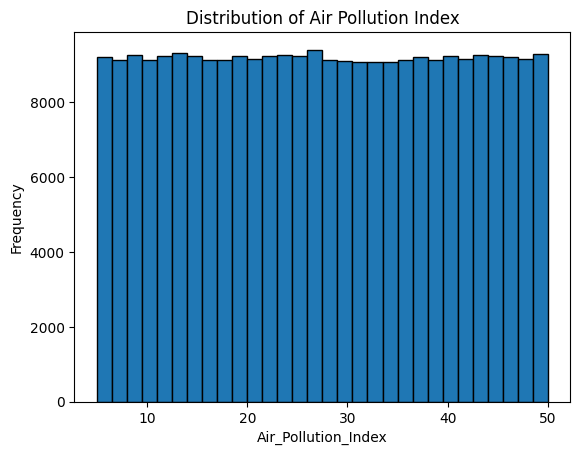

In [17]:
df["Air_Pollution_Index"].plot(kind="hist", bins=30, edgecolor="black")
plt.title("Distribution of Air Pollution Index")
plt.xlabel("Air_Pollution_Index")
plt.show()


With 275k+ rows, plotting every point individually is unreadable, so the categorical comparisons below use grouped averages/rates rather than one bar per record.

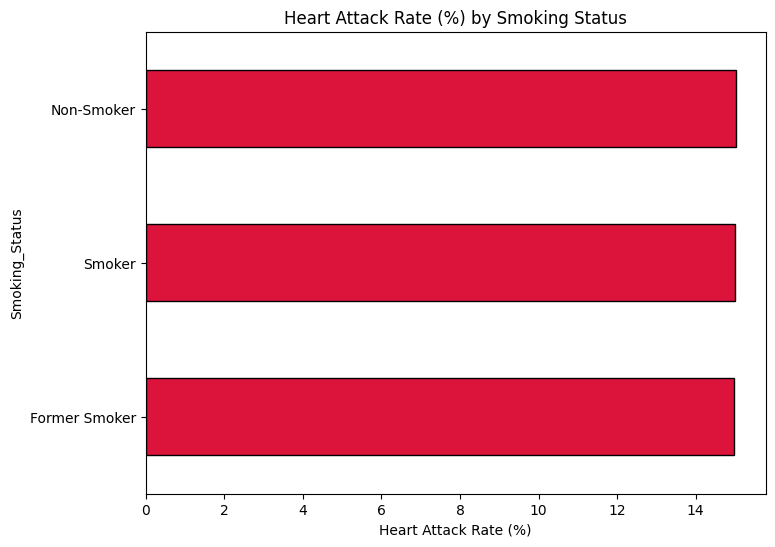

In [18]:
rate_by_smoking = df.groupby('Smoking_Status')['Heart_Attack_Incidence'].mean() * 100

plt.figure(figsize=(8, 6))
rate_by_smoking.sort_values().plot(kind='barh', color='crimson', edgecolor='black')
plt.title("Heart Attack Rate (%) by Smoking Status")
plt.xlabel("Heart Attack Rate (%)")
plt.show()


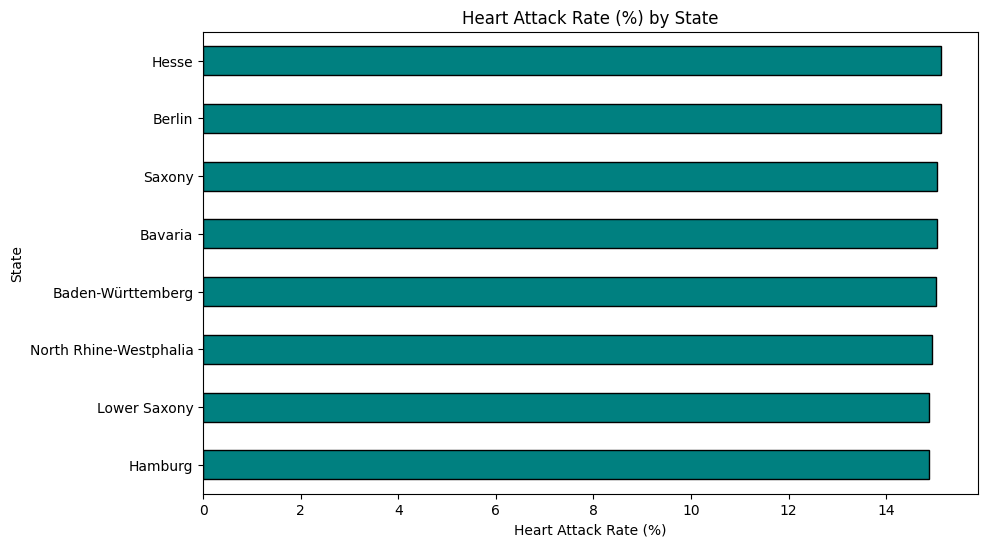

In [19]:
rate_by_state = df.groupby('State')['Heart_Attack_Incidence'].mean().sort_values() * 100

plt.figure(figsize=(10, 6))
rate_by_state.plot(kind='barh', color='teal', edgecolor='black')
plt.title("Heart Attack Rate (%) by State")
plt.xlabel("Heart Attack Rate (%)")
plt.show()


In [20]:
BMI_Group = df.groupby('Smoking_Status')['BMI'].mean()
print(BMI_Group)


Smoking_Status
Former Smoker    24.996249
Non-Smoker       25.003392
Smoker           24.978353
Name: BMI, dtype: float64


In [21]:
Chol_stats = df.groupby("Diet_Quality")["Cholesterol_Level"].agg(["max", "min", "mean"])
Chol_stats


,max,min,mean
Diet_Quality,,,
Average,259.5,-7.9,129.962737
Good,248.0,4.6,130.116447
Poor,272.4,5.7,130.023112


In [22]:
Incidence_by_age = df.groupby("Age_Group")["Heart_Attack_Incidence"].agg(["mean", "sum", "count"])
Incidence_by_age


,mean,sum,count
Age_Group,,,
Adult,0.150957,29152,193115
Youth,0.147996,12214,82529


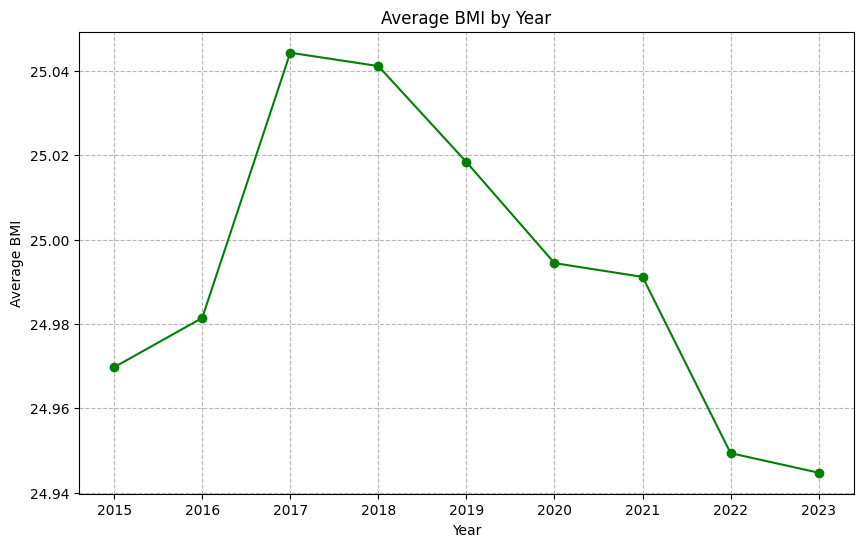

In [23]:
avg_bmi_by_year = df.groupby('Year')['BMI'].mean()

plt.figure(figsize=(10, 6))
plt.plot(avg_bmi_by_year.index, avg_bmi_by_year.values, marker='o', linestyle='-', color='green')
plt.title('Average BMI by Year')
plt.xlabel('Year')
plt.ylabel('Average BMI')
plt.grid(True, linestyle='--', alpha=0.9)
plt.show()


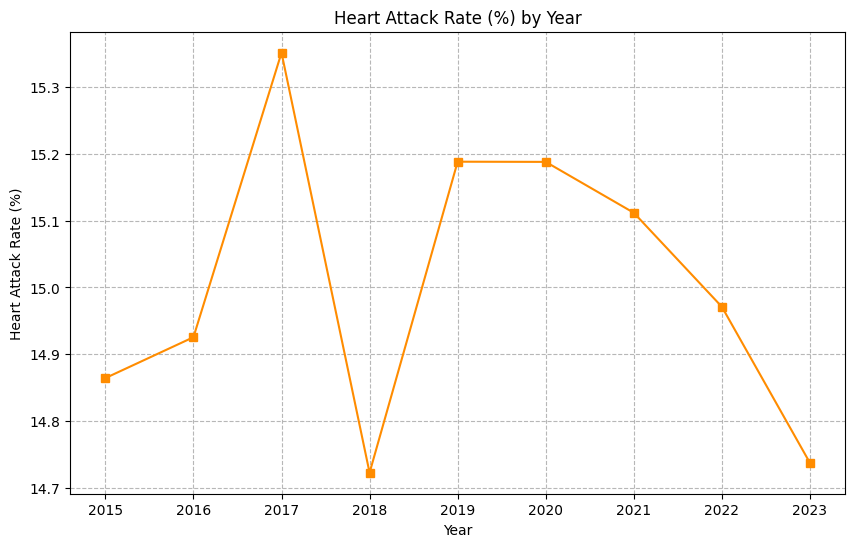

In [24]:
rate_by_year = df.groupby('Year')['Heart_Attack_Incidence'].mean() * 100

plt.figure(figsize=(10, 6))
plt.plot(rate_by_year.index, rate_by_year.values, marker='s', linestyle='-', color='darkorange')
plt.title('Heart Attack Rate (%) by Year')
plt.xlabel('Year')
plt.ylabel('Heart Attack Rate (%)')
plt.grid(True, linestyle='--', alpha=0.9)
plt.show()


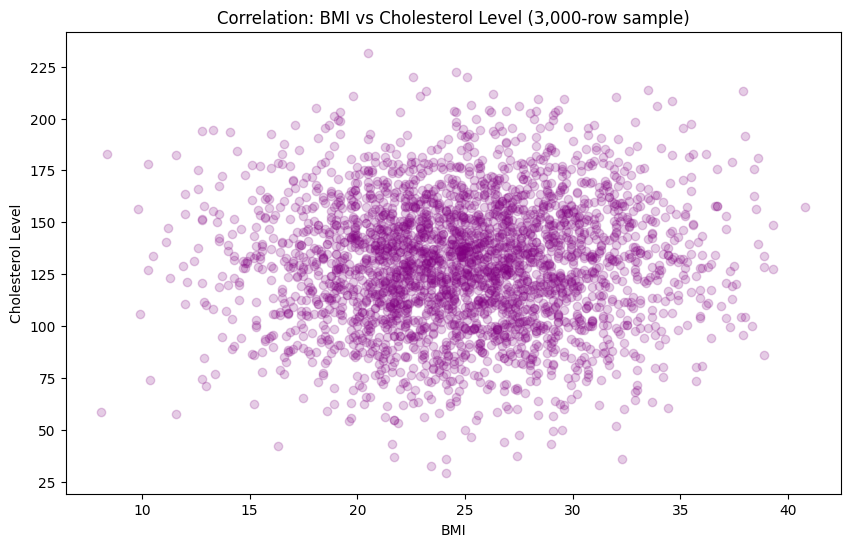

In [25]:
sample = df.sample(3000, random_state=42)

plt.figure(figsize=(10, 6))
plt.scatter(sample['BMI'], sample['Cholesterol_Level'], alpha=0.2, color='purple')
plt.title('Correlation: BMI vs Cholesterol Level (3,000-row sample)')
plt.xlabel('BMI')
plt.ylabel('Cholesterol Level')
plt.show()


<Figure size 800x600 with 0 Axes>

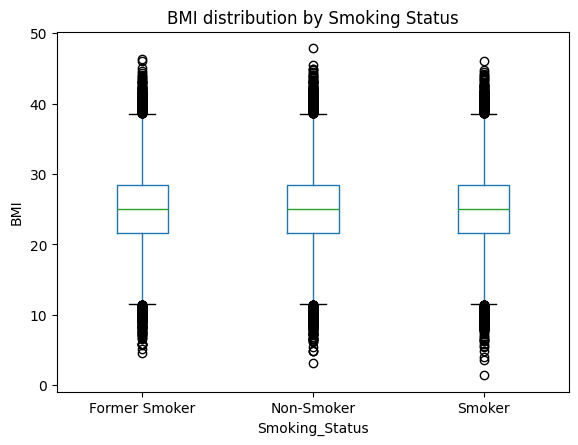

In [26]:
plt.figure(figsize=(8, 6))
df.boxplot(column='BMI', by='Smoking_Status', grid=False)
plt.title('BMI distribution by Smoking Status')
plt.suptitle('')
plt.ylabel('BMI')
plt.show()


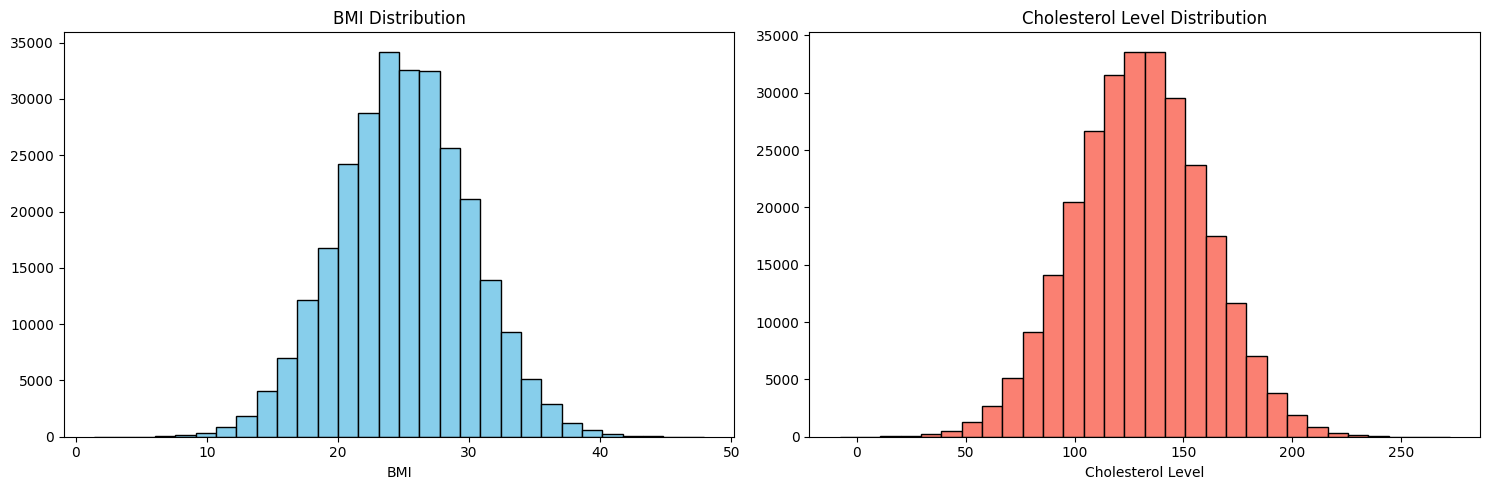

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(df['BMI'], bins=30, color='skyblue', edgecolor='black')
axes[0].set_title('BMI Distribution')
axes[0].set_xlabel('BMI')

axes[1].hist(df['Cholesterol_Level'], bins=30, color='salmon', edgecolor='black')
axes[1].set_title('Cholesterol Level Distribution')
axes[1].set_xlabel('Cholesterol Level')

plt.tight_layout()
plt.show()


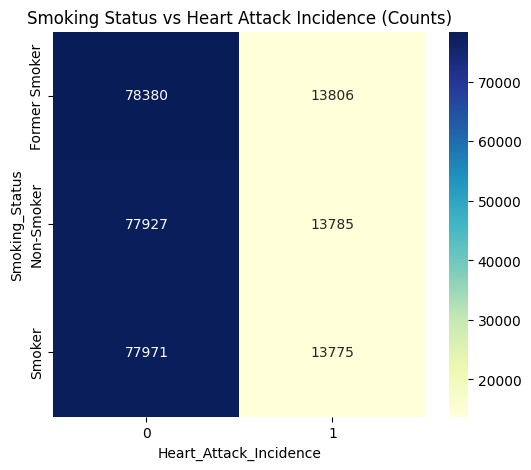

In [28]:
ct_smoke_incidence = pd.crosstab(df['Smoking_Status'], df['Heart_Attack_Incidence'])

plt.figure(figsize=(6, 5))
sns.heatmap(ct_smoke_incidence, annot=True, fmt="d", cmap="YlGnBu")
plt.title("Smoking Status vs Heart Attack Incidence (Counts)")
plt.xlabel("Heart_Attack_Incidence")
plt.ylabel("Smoking_Status")
plt.show()


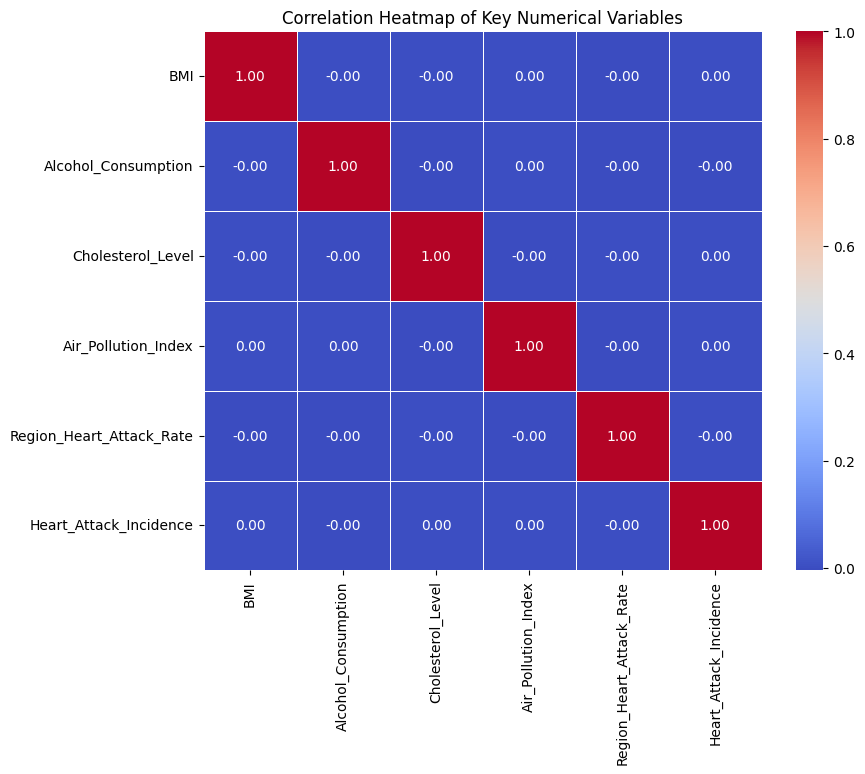

In [29]:
num_cols = ['BMI', 'Alcohol_Consumption', 'Cholesterol_Level', 'Air_Pollution_Index',
            'Region_Heart_Attack_Rate', 'Heart_Attack_Incidence']
corr = df[num_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title('Correlation Heatmap of Key Numerical Variables')
plt.show()


In [30]:
age_bmi_pivot = df.pivot_table(values="BMI", index="Age_Group", aggfunc=["max", "mean", "min"])
age_bmi_pivot


,max,mean,min
,BMI,BMI,BMI
Age_Group,,,
Adult,47.9,24.996758,1.4
Youth,45.1,24.983102,5.4


In [31]:
total_records = len(df)
avg_bmi = df["BMI"].mean()
avg_cholesterol = df["Cholesterol_Level"].mean()
top_smoking_group = df.groupby("Smoking_Status")["Heart_Attack_Incidence"].mean().idxmax()
highest_rate_state = df.groupby("State")["Heart_Attack_Incidence"].mean().idxmax()
overall_incidence_pct = df["Heart_Attack_Incidence"].mean() * 100
ct_gender_incidence = pd.crosstab(df["Gender"], df["Heart_Attack_Incidence"])

print("Total records analysed:", total_records)
print("Average BMI:", round(avg_bmi, 2))
print("Average Cholesterol Level:", round(avg_cholesterol, 2))
print("Smoking status with highest heart attack rate:", top_smoking_group)
print("State with highest heart attack rate:", highest_rate_state)
print("Overall heart attack incidence rate:", round(overall_incidence_pct, 2), "%")
print("Crosstab of Gender vs Heart Attack Incidence:\n", ct_gender_incidence)


Total records analysed: 275644
Average BMI: 24.99
Average Cholesterol Level: 130.03
Smoking status with highest heart attack rate: Non-Smoker
State with highest heart attack rate: Hesse
Overall heart attack incidence rate: 15.01 %
Crosstab of Gender vs Heart Attack Incidence:
 Heart_Attack_Incidence      0      1
Gender                              
Female                  78569  13602
Male                    77850  13751
Other                   77859  14013


In [32]:
bmi = df['BMI'].to_numpy()
cholesterol = df['Cholesterol_Level'].to_numpy()
alcohol = df['Alcohol_Consumption'].to_numpy()
pollution = df['Air_Pollution_Index'].to_numpy()
incidence = df['Heart_Attack_Incidence'].to_numpy()

print("BMI:", bmi[:5])
print("Cholesterol:", cholesterol[:5])
print("Alcohol Consumption:", alcohol[:5])
print("Air Pollution Index:", pollution[:5])
print("BMI dtype:", bmi.dtype)


BMI: [25.6 36.7 28.6 27.6 15.2]
Cholesterol: [154.4  75.  121.9 152.3 130.3]
Alcohol Consumption: [ 4.2  2.4 29.5  4.2  4.3]
Air Pollution Index: [31.58 46.22 15.69 26.5  11.21]
BMI dtype: float64


In [33]:
print("Average BMI is:", round(np.mean(bmi), 2))
print("Highest Cholesterol found is:", np.max(cholesterol))
print("Lowest Cholesterol found is:", np.min(cholesterol))
print("Average Alcohol Consumption is:", round(np.mean(alcohol), 2))
print("Overall Heart Attack Incidence Rate:", round(np.mean(incidence) * 100, 2), "%")


Average BMI is: 24.99
Highest Cholesterol found is: 272.4
Lowest Cholesterol found is: -7.9
Average Alcohol Consumption is: 4.99
Overall Heart Attack Incidence Rate: 15.01 %


In [34]:
columns = [bmi, cholesterol, alcohol, pollution]
column_names = ["BMI", "Cholesterol_Level", "Alcohol_Consumption", "Air_Pollution_Index"]

summary_list = []
for data in columns:
    stats = {
        "Mean (Avg)": round(np.mean(data), 2),
        "Std Dev (Spread)": round(np.std(data), 2),
        "Total (Sum)": round(np.sum(data), 2),
        "Highest (Max)": round(np.max(data), 2),
        "Lowest (Min)": round(np.min(data), 2),
        "Count": len(data),
    }
    summary_list.append(stats)

summary_table = pd.DataFrame(summary_list, index=column_names)
summary_table


,Mean (Avg),Std Dev (Spread),Total (Sum),Highest (Max),Lowest (Min),Count
BMI,24.99,5.00,6889079.30,47.9,1.4,275644
Cholesterol_Level,130.03,30.01,35843154.90,272.4,-7.9,275644
Alcohol_Consumption,4.99,5.00,1374287.60,70.0,0.0,275644
Air_Pollution_Index,27.49,13.00,7576413.02,50.0,5.0,275644


In [35]:
summary_table.to_csv("heart_attack_summary.csv")
print("Saved summary table to heart_attack_summary.csv")


Saved summary table to heart_attack_summary.csv
